# Детекция рыночных аномалий: этап 1 (данные, корреляции, графы) и этап 2 (бейзлайны)

**Исправленная версия.** Что изменено по сравнению с `main.ipynb` / `main_1.ipynb`:

1. Средняя корреляция считается по **доходностям**, а не по ценам (корреляция уровней цен ложная).
2. Дата окна = дата его **последнего** дня (раньше бралась дата следующего дня).
3. Разметка учитывает «память» окна: окно в 60 дней содержит кризис ещё ~60 торговых дней после его конца. Оценка идёт в двух вариантах (`strict` и `memory`) и дополнительно **по событиям** (поймали кризис или нет, с какой задержкой, сколько ложных тревог).
4. Кризисные периоды относятся к американскому рынку (убран «мобилизационный шок»).
5. Графы 2017 и 2020 строятся на окнах одинаковой длины по одним и тем же логдоходностям.
6. Добавлены адаптивный порог (использует только прошлое), оценка PELT по событиям и перебор `penalty`.
7. `prices.csv` не перезаписывается пустой таблицей, если загрузка yfinance не удалась.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

WINDOW = 60                 # длина окна, торговых дней
STEP = 5                    # шаг окна, торговых дней
TRAIN_END = "2020-01-01"    # всё, что раньше, это обучающая часть
START, END = "2015-01-01", "2025-12-31"
PRICES_CSV = Path("prices.csv")

In [2]:
tickers = [
    # Технологии
    "AAPL","MSFT","GOOGL","META","NVDA","INTC","CSCO","ORCL","IBM","TXN",
    "QCOM","ADBE","CRM","AVGO","AMAT","MU",
    # Финансы
    "JPM","BAC","WFC","C","GS","MS","USB","PNC","AXP","BLK","SCHW","MET","AIG","TRV",
    # Здравоохранение
    "JNJ","PFE","MRK","ABT","UNH","LLY","AMGN","BMY","MDT","GILD","CVS",
    # Товары повседневного спроса
    "PG","KO","PEP","WMT","COST","MDLZ","CL","MO","PM","KMB",
    # Энергетика
    "XOM","CVX","COP","SLB","EOG","OXY",
    # Промышленность
    "BA","CAT","GE","HON","UPS","MMM","LMT","DE","UNP",
    # Потребительский сектор (циклический)
    "AMZN","HD","MCD","NKE","SBUX","LOW","TGT","F","GM",
    # Коммунальные услуги
    "DUK","SO","NEE","D","EXC",
    # Связь и медиа
    "T","VZ","CMCSA","DIS",
    # Материалы и недвижимость
    "NEM","FCX","AMT","SPG","PLD",
]


MIN_TICKERS = 30   # меньше тикеров, значит загрузка прошла плохо


def clean_prices(p):
    """Оставляем тикеры с полной историей и сообщаем, сколько отброшено."""
    if isinstance(p, pd.Series):
        p = p.to_frame()
    all_nan = [c for c in p.columns if p[c].isna().all()]
    cleaned = p.dropna(axis=1)
    print(f"Колонок до очистки: {p.shape[1]}, полностью пустых: {len(all_nan)}, "
          f"после dropna(axis=1): {cleaned.shape[1]}")
    return cleaned


def download_prices(retries=3):
    import time
    import yfinance as yf
    cleaned = None
    for attempt in range(1, retries + 1):
        data = yf.download(tickers, start=START, end=END, auto_adjust=True,
                           progress=False, threads=False)
        if len(data) > 0 and "Close" in data:
            cleaned = clean_prices(data["Close"])
        else:
            cleaned = pd.DataFrame()
        if cleaned.shape[1] >= MIN_TICKERS:
            return cleaned
        print(f"Попытка {attempt}/{retries}: получено мало тикеров, ждём и пробуем снова")
        time.sleep(5 * attempt)
    raise RuntimeError(
        f"Не удалось скачать цены: получено тикеров {0 if cleaned is None else cleaned.shape[1]} "
        f"(нужно минимум {MIN_TICKERS}). Вероятно, лимиты или сбой yfinance. "
        "Подожди несколько минут, обнови библиотеку (pip install -U yfinance) и перезапусти ячейку. "
        "prices.csv не перезаписан."
    )


def load_prices():
    """Берём prices.csv, если он годный. Иначе скачиваем заново и сохраняем только годный результат."""
    if PRICES_CSV.exists():
        p = pd.read_csv(PRICES_CSV, index_col=0, parse_dates=True)
        print(f"{PRICES_CSV}: форма {p.shape}")
        cleaned = clean_prices(p) if len(p) > 0 else pd.DataFrame()
        if cleaned.shape[1] >= MIN_TICKERS:
            return cleaned
        print(f"{PRICES_CSV} непригоден (пустой или почти все тикеры пустые), скачиваем заново")

    p = download_prices()
    p.to_csv(PRICES_CSV)
    return p


prices = load_prices()
returns = np.log(prices).diff().dropna()      # логдоходности, их используем везде

assert len(returns) > WINDOW, "Слишком мало данных: проверь загрузку цен"
print("Цены:", prices.shape, "| Доходности:", returns.shape)
print("Период:", returns.index[0].date(), "->", returns.index[-1].date())

prices.csv: форма (2765, 84)
Колонок до очистки: 84, полностью пустых: 0, после dropna(axis=1): 84
Цены: (2765, 84) | Доходности: (2764, 84)
Период: 2015-01-05 -> 2025-12-30


In [3]:
def rolling_mean_corr(returns, window=WINDOW, step=STEP):
    """Средняя попарная корреляция доходностей в скользящем окне.
    Индекс результата = дата ПОСЛЕДНЕГО дня окна, win_start = дата первого дня окна."""
    if returns.shape[1] < 2:
        raise ValueError(f"Нужно минимум 2 акции, сейчас {returns.shape[1]}: проверь prices.csv")
    iu = np.triu_indices(returns.shape[1], k=1)
    vals, ends, starts = [], [], []
    for end in range(window, len(returns) + 1, step):
        w = returns.iloc[end - window:end]            # строки end-window ... end-1
        corr = np.corrcoef(w.values, rowvar=False)
        vals.append(np.nanmean(corr[iu]))
        ends.append(returns.index[end - 1])
        starts.append(returns.index[end - window])
    return pd.DataFrame({"mean_corr": vals, "win_start": starts}, index=pd.DatetimeIndex(ends))


df_metrics = rolling_mean_corr(returns)
X = df_metrics["mean_corr"]
print("Окон:", len(df_metrics), "| mean_corr: min %.2f, median %.2f, max %.2f" % (X.min(), X.median(), X.max()))

Окон: 541 | mean_corr: min 0.06, median 0.26, max 0.75


## Кризисные события (американский рынок)

Даты нужно сверить с источниками и обосновать в тексте ВКР:

- **COVID-19:** пик индекса S&P 500 19 февраля 2020, минимум 23 марта 2020, паника до конца апреля.
- **Начало 2022:** вторжение в Украину (24 февраля) и первое повышение ставки ФРС (16 марта).
- **Осень 2022:** сильный отчёт по инфляции CPI (13 сентября) и повышение ставки ФРС (21 сентября), минимум индекса в середине октября.
- **Март 2023:** крах Silicon Valley Bank (10 марта) и банковский кризис.

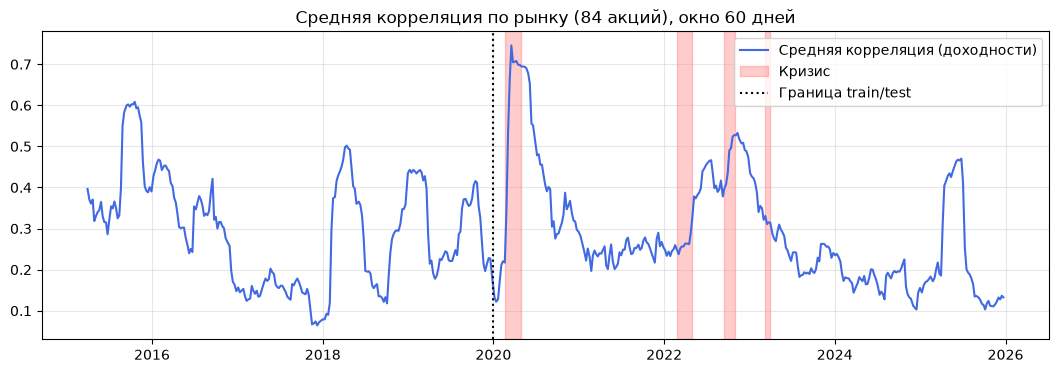

In [4]:
CRISES = {
    "COVID-19":                     ("2020-02-20", "2020-04-30"),
    "Начало 2022 (ФРС, геополит.)": ("2022-02-24", "2022-04-30"),
    "Осень 2022 (CPI, ФРС)":        ("2022-09-13", "2022-10-31"),
    "Март 2023 (SVB)":              ("2023-03-08", "2023-03-31"),
}

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df_metrics.index, X, color="royalblue", label="Средняя корреляция (доходности)")
for i, (name, (s, e)) in enumerate(CRISES.items()):
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="red", alpha=0.2, label="Кризис" if i == 0 else None)
ax.axvline(pd.Timestamp(TRAIN_END), color="black", linestyle=":", label="Граница train/test")
ax.set_title(f"Средняя корреляция по рынку ({returns.shape[1]} акций), окно {WINDOW} дней")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## 1. Корреляционные графы: спокойный период и кризис

Окна одинаковой длины (по числу торговых дней), корреляции по тем же логдоходностям, что и выше.

Спокойный период: 2017-01-03 - 2017-03-01, рёбер 159, плотность 0.046
Паника:           2020-03-02 - 2020-04-27, рёбер 3166, плотность 0.908


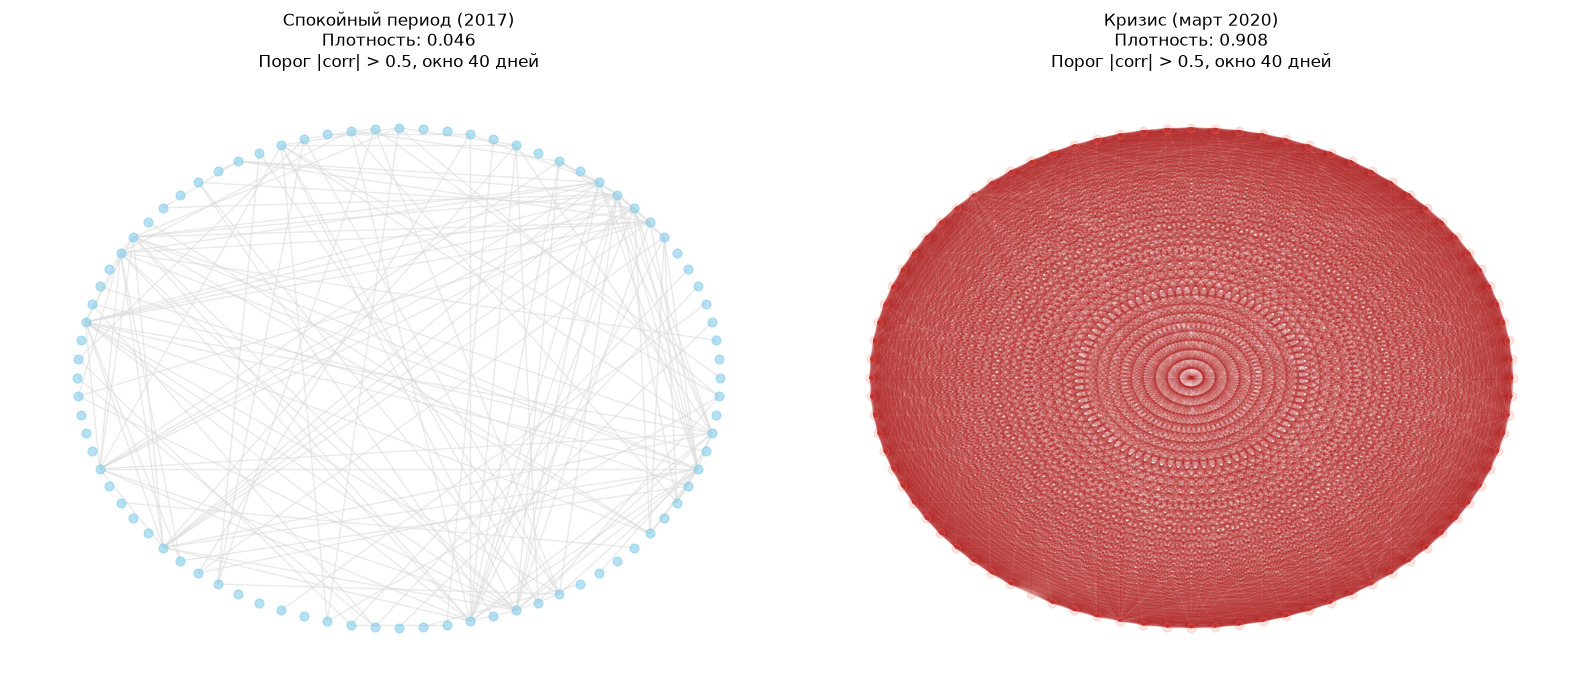

In [5]:
import networkx as nx

N_DAYS = 40
THRESHOLD = 0.5

calm_window = returns.loc["2017-01-01":].iloc[:N_DAYS]
panic_window = returns.loc["2020-03-01":].iloc[:N_DAYS]


def build_correlation_graph(window_data, threshold=THRESHOLD):
    corr = window_data.corr()
    cols = list(corr.columns)
    r_idx, c_idx = np.triu_indices_from(corr, k=1)
    mask = np.abs(corr.values[r_idx, c_idx]) > threshold

    G = nx.Graph()
    G.add_nodes_from(cols)
    for r, c in zip(r_idx[mask], c_idx[mask]):
        G.add_edge(cols[r], cols[c], weight=corr.values[r, c])
    return G


G_calm = build_correlation_graph(calm_window)
G_panic = build_correlation_graph(panic_window)
print(f"Спокойный период: {calm_window.index[0].date()} - {calm_window.index[-1].date()}, "
      f"рёбер {G_calm.number_of_edges()}, плотность {nx.density(G_calm):.3f}")
print(f"Паника:           {panic_window.index[0].date()} - {panic_window.index[-1].date()}, "
      f"рёбер {G_panic.number_of_edges()}, плотность {nx.density(G_panic):.3f}")

pos_fixed = nx.circular_layout(list(returns.columns))
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, G, color, edge_color, alpha, title in [
    (axes[0], G_calm, "skyblue", "gainsboro", 0.6, f"Спокойный период (2017)\nПлотность: {nx.density(G_calm):.3f}"),
    (axes[1], G_panic, "salmon", "firebrick", 0.2, f"Кризис (март 2020)\nПлотность: {nx.density(G_panic):.3f}"),
]:
    nx.draw(G, pos=pos_fixed, ax=ax, node_size=40, node_color=color,
            edge_color=edge_color, alpha=alpha, with_labels=False)
    ax.set_title(title + f"\nПорог |corr| > {THRESHOLD}, окно {N_DAYS} дней", fontsize=12)
plt.tight_layout()
plt.show()

Сравни плотности графов, выведенные выше: после перезапуска ноутбука запиши здесь вывод по своим числам.

## 2. Baseline solution

Три метода:

1. **Статический порог:** квантиль средней корреляции на train.
2. **Адаптивный порог:** робастный z-score относительно предыдущего года (только прошлое, без утечки), чтобы учесть смену уровня корреляций со временем.
3. **PELT:** поиск точек излома. Это **офлайн**-метод (смотрит на весь ряд сразу), поэтому его сравнение с первыми двумя нужно подавать в тексте как справочное.

### Разметка окон

- `strict`: окно помечено, если его **последний день** внутри кризиса.
- `memory`: окно помечено, если в нём не меньше `MIN_OVERLAP` торговых дней кризиса. Так учитывается, что окно ещё «помнит» кризис.

#### 1. Разметка массива кризисных дней.
1. берет данный из массива кризисов о тех кризисах которые произошли
2. размечает кризисные дни: в период с начала по конец ставиться в эти дни значение True в остальные False

In [6]:
crisis_day = pd.Series(False, index=returns.index)
for s, e in CRISES.values():
    crisis_day.loc[s:e] = True

MIN_OVERLAP = 10   # минимум торговых дней кризиса в окне для варианта memory

y_strict = crisis_day.reindex(df_metrics.index).astype(int)
overlap = pd.Series(
    [int(crisis_day.loc[s:e].sum()) for s, e in zip(df_metrics["win_start"], df_metrics.index)],
    index=df_metrics.index,
)
y_memory = (overlap >= MIN_OVERLAP).astype(int)

train_mask = df_metrics.index < TRAIN_END
test_mask = ~train_mask

for name, y in [("strict", y_strict), ("memory", y_memory)]:
    print(f"{name:7s}: аномальных окон {y.sum():3d} из {len(y)} ({100*y.mean():.1f}%), "
          f"в train {y[train_mask].sum()}, в test {y[test_mask].sum()}")

strict : аномальных окон  30 из 541 (5.5%), в train 0, в test 30
memory : аномальных окон  63 из 541 (11.6%), в train 0, в test 63


#### 2. Кастомный валидационный фреймворк
Алгоритмы реализует оценку по макроэкономическим событиям. Он проверяет, насколько детектор полезен инвестору на практике.

Функция `event_metrics` оценка по событиям. Каждый кризис оборачивается на допустимое временное окно от lo левая граница до hi правая граница.
- lo раздвигается на 14 дней назад. Если модель забила тревогу за пару недель до официального обвала.
- hi раздвигается на 84 календарных дня вперед 
Обнаружение: Код идет по циклам и если в разрешенном интервале lo - hi была хоть одна тревога от модели, то этот кризис обнаружен.
Задержка: Код берет дату самой первой тревоги внутри этого окна и вычитает из неё официальную дату начала кризиса. Получается задержка в днях. Если число отрицательное — модель сработала на опережение.

Обьединение подряд идущих тревог. Затем производиться проверка: если ни один день из этой серии тревог не попал в разрешенные зоны кризисов, значит, модель запаниковала абсолютно зря.

Функция `add_row` запись результатов (расчет метрик Precision — точность, Recall — полноту, F1-score — их баланс для переменных strict и memory и показатели количества пойманных кризисов, задержку и ложные тревоги) в таблицу.

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score

EARLY_DAYS = 14   # тревога не раньше чем за 2 недели до начала кризиса
LATE_DAYS = 84    # ~60 торговых дней после конца кризиса (память окна)


def event_metrics(alarm):
    """Оценка по событиям. alarm: булев ряд на сетке окон (только тестовая часть)."""
    alarm = alarm.astype(bool)
    allowed, detected, delays = [], 0, []
    for s, e in CRISES.values():
        s, e = pd.Timestamp(s), pd.Timestamp(e)
        lo, hi = s - pd.Timedelta(days=EARLY_DAYS), e + pd.Timedelta(days=LATE_DAYS)
        allowed.append((lo, hi))
        hits = alarm[(alarm.index >= lo) & (alarm.index <= hi)]
        hits = hits[hits]
        if len(hits):
            detected += 1
            delays.append((hits.index[0] - s).days)

    # эпизоды тревог = подряд идущие окна с тревогой; ложный эпизод не попадает ни в один кризис
    run_id = alarm.ne(alarm.shift(fill_value=False)).cumsum()
    episodes = [grp.index for _, grp in alarm[alarm].groupby(run_id[alarm])]
    false_eps = sum(
        not any(lo <= d <= hi for d in idx for lo, hi in allowed)
        for idx in episodes
    )
    return {
        "Поймано кризисов": f"{detected}/{len(CRISES)}",
        "Задержка, дней (среднее)": float(np.mean(delays)) if delays else np.nan,
        "Ложных эпизодов": false_eps,
    }


rows = []
def add_row(name, alarm, window_level=True):
    row = {"Метод": name}
    for lab, y in (("strict", y_strict), ("memory", y_memory)):
        if window_level:
            row[f"P {lab}"] = precision_score(y[test_mask], alarm[test_mask], zero_division=0)
            row[f"R {lab}"] = recall_score(y[test_mask], alarm[test_mask], zero_division=0)
            row[f"F1 {lab}"] = f1_score(y[test_mask], alarm[test_mask], zero_division=0)
        else:
            row[f"P {lab}"] = row[f"R {lab}"] = row[f"F1 {lab}"] = np.nan
    row.update(event_metrics(alarm[test_mask]))
    rows.append(row)

#### 3. Детекторы паники статический и адитивный порог

##### Статический порог

Определяется уровень корреляции, выше которого рынок забирался только в 5% случаев (\(q=0.95\)) или всего в 1% случаев (\(q=0.99\)). Это число становится нашей потолком. Если в будущем корреляция пробивает этот потолок — модель считает, что наступила аномалия, и включает сигнал тревоги.

##### Адаптивный порог

- Сдвигаем данный на один шаг назад для предотвращения заглядывания в будущее.
- На этом скользящем отрезке код рассчитывает «робастный Z-score» (продвинутую оценку отклонения). Вместо классического среднего и стандартного отклонения он использует медиану и MAD (медианное абсолютное отклонение).
- Если сегодняшняя корреляция оказывается выше недавней нормы более чем на 3 таких «умных» отклонения (Z_THR = 3.0) то модель обьявляет тревогу.

In [8]:
# 1) Статический порог: квантиль на train (в train нет COVID и событий 2022-2023)
for q in (0.95, 0.99):
    thr = X[train_mask].quantile(q)
    alarm = (X > thr).astype(int)
    add_row(f"Статический порог (q={q}, thr={thr:.3f})", alarm)

# 2) Адаптивный порог: робастный z-score относительно предыдущих LOOKBACK окон (только прошлое)
LOOKBACK = 50     # ~250 торговых дней при шаге 5
Z_THR = 3.0

past = X.shift(1)
roll_med = past.rolling(LOOKBACK, min_periods=20).median()
roll_mad = past.rolling(LOOKBACK, min_periods=20).apply(lambda v: np.median(np.abs(v - np.median(v))), raw=True)
robust_z = (X - roll_med) / (1.4826 * roll_mad)
alarm_adapt = (robust_z > Z_THR).fillna(False).astype(int)
add_row(f"Адаптивный порог (z>{Z_THR}, lookback={LOOKBACK})", alarm_adapt)

##### 4. Поиск точек излома 

Офлайн-алгоритм PELT (Change Point Detection):
1. Преобразуем данные если это необходимо в двухмерную матрицу
2. Насройка модели. Миниму 10 шагов между точками излома, проверка каждого дня, модель "l2" означает, что он ищет изменения в среднем значении графика (минимизирует сумму квадратов отклонени

In [9]:
import ruptures as rpt

signal = X.values.reshape(-1, 1)


def pelt_alarm(pen):
    algo = rpt.Pelt(model="l2", min_size=10, jump=1).fit(signal)
    bkps = algo.predict(pen=pen)[:-1]          # индексы начала нового режима
    mask = pd.Series(False, index=X.index)
    if bkps:
        mask.iloc[bkps] = True
    return mask


# Перебор penalty: сколько точек излома и как они соотносятся с кризисами (тестовая часть)
sweep = []
for pen in (0.05, 0.1, 0.2, 0.5, 1.0):
    m = pelt_alarm(pen)
    ev = event_metrics(m[test_mask])
    sweep.append({"penalty": pen, "Точек излома (всего)": int(m.sum()), **ev})
pd.DataFrame(sweep)

,penalty,Точек излома (всего),Поймано кризисов,"Задержка, дней (среднее)",Ложных эпизодов
0,0.05,22,3/4,59.000000,6
1,0.10,18,3/4,61.333333,4
2,0.20,14,3/4,32.000000,3
3,0.50,6,3/4,32.000000,1
4,1.00,3,1/4,13.000000,1


PENALTY = 0.5: точек излома 6
   2016-11-28
   2018-02-07
   2020-03-04
   2020-08-03
   2022-05-09
   2023-03-17


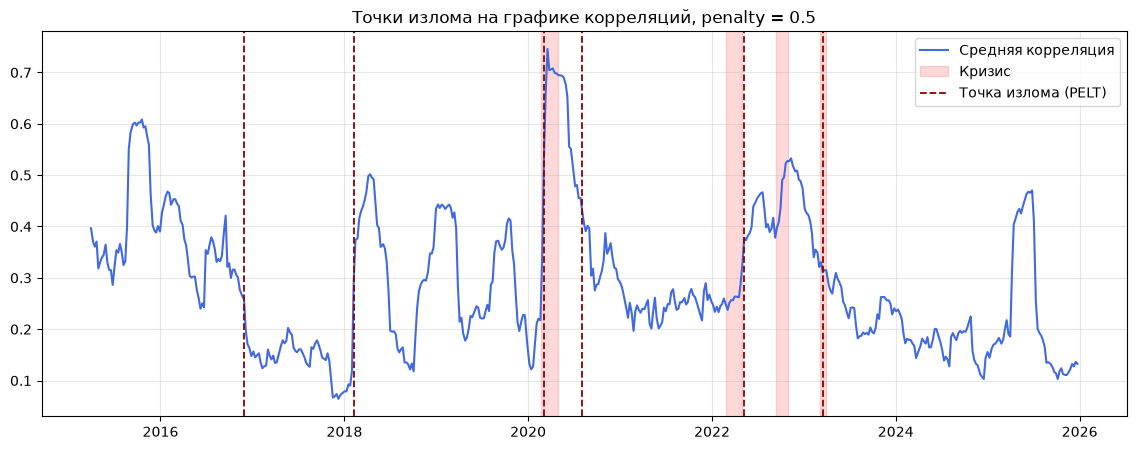

In [10]:
PENALTY = 0.5   # выбери по таблице выше
alarm_pelt = pelt_alarm(PENALTY)
cp_dates = list(X.index[alarm_pelt.values])
print(f"PENALTY = {PENALTY}: точек излома {len(cp_dates)}")
for d in cp_dates:
    print("  ", d.date())

add_row(f"PELT (penalty={PENALTY}), офлайн", alarm_pelt.astype(int), window_level=False)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(X.index, X, color="royalblue", label="Средняя корреляция")
for i, (name, (s, e)) in enumerate(CRISES.items()):
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="red", alpha=0.15, label="Кризис" if i == 0 else None)
for i, d in enumerate(cp_dates):
    ax.axvline(d, color="darkred", linestyle="--", linewidth=1.3, label="Точка излома (PELT)" if i == 0 else None)
ax.set_title(f"Точки излома на графике корреляций, penalty = {PENALTY}")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

In [11]:
results = pd.DataFrame(rows).set_index("Метод")
results.round(3)

,P strict,R strict,F1 strict,P memory,R memory,F1 memory,Поймано кризисов,"Задержка, дней (среднее)",Ложных эпизодов
Метод,,,,,,,,,
"Статический порог (q=0.95, thr=0.504)",0.458,0.367,0.407,1.000,0.381,0.552,2/4,25.500,0
"Статический порог (q=0.99, thr=0.602)",0.615,0.267,0.372,1.000,0.206,0.342,1/4,20.000,0
"Адаптивный порог (z>3.0, lookback=50)",0.255,0.400,0.312,0.489,0.365,0.418,3/4,22.667,1
"PELT (penalty=0.5), офлайн",NaN,NaN,NaN,NaN,NaN,NaN,3/4,32.000,1


## Ограничения (для раздела ВКР)

- Кризисов всего четыре, поэтому все метрики шумные: разница в один пойманный кризис меняет картину.
- Метки задаются вручную, результат зависит от выбранных дат и от `MIN_OVERLAP`. Поэтому приводятся оба варианта разметки и оценка по событиям.
- В train нет COVID и событий 2022–2023, но есть декабрь 2018 (падение рынка), поэтому статический порог частично «знает» о стрессе.
- Уровень средней корреляции может смещаться со временем, это проверяет адаптивный порог.
- PELT работает офлайн и использует будущее. В реальном детекторе так делать нельзя.
- Выживший выбор тикеров: берутся компании, которые есть сегодня и торговались весь период.

## 2. РСА solution

Для дтекции рыночных аномалий PCA применяют двумя классическими способами:

1. Absorption Ratio (Доля объясненной дисперсии первых компонент): Во время паники все акции падают вместе. Это значит, что 1-я главная компонента (общий рыночный фактор) начинает объяснять огромную долю всех движений рынка (дисперсия резко подскакивает).
2. Ошибка восстановления (Reconstruction Error): Мы обучаем PCA на спокойном train периоде (до 2020 года), а затем прогоняем через него новые дни/окна. Когда начинается кризис, привычная структура рынка ломается, и ошибка восстановления взлетает.

Этапы работы PCA:
### Математические шаги алгоритма в скользящем окне

Для каждого временного окна $W$ размером $T = 60$ торговых дней и $N = 84$ акций выполняются четыре последовательных преобразования:

1. **Стандартизация (Z-преобразование) — `StandardScaler()`**
   Для каждой акции $j$ внутри окна вычисляются выборочное среднее $\mu_j$ и стандартное отклонение (волатильность) $\sigma_j$, после чего доходности приводятся к единому масштабу:
   $$z_{t,j} = \frac{r_{t,j} - \mu_j}{\sigma_j}$$
   *Зачем нужно:* Уравнять вклад всех компаний. Без стандартизации высоковолатильные акции (например, технологический сектор) с большей дисперсией доминировали бы над защитными бумагами, искажая главные компоненты.

2. **Построение корреляционной матрицы — $R$**
   На стандартизированных данных вычисляется ковариационная матрица $R = \frac{1}{T - 1} Z^T Z$ размером $84 \times 84$, которая после Z-преобразования совпадает с **матрицей попарных корреляций Пирсона**.
   *Зачем нужно:* Матрица $R$ фиксирует актуальную структуру взаимосвязей между активами внутри текущего 60-дневного окна.

3. **Спектральное разложение (Собственные векторы и собственные значения / SVD)**
   Симметричная матрица $R$ раскладывается на ортогональные собственные векторы $v_1, v_2, \dots, v_N$ и соответствующие им неотрицательные собственные значения $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_N \ge 0$:
   $$R v_k = \lambda_k v_k$$
   * **Собственные векторы ($v_k$)** задают новые некоррелированные оси (главные компоненты). Первый вектор $v_1$ соответствует общему рыночному фактору, последующие ($v_2, v_3, \dots$) — отраслевым и стилевым факторам.
   * **Собственные значения ($\lambda_k$)** измеряют величину дисперсии (энергии рынка), приходящуюся на $k$-ю компоненту. После стандартизации сумма всех собственных значений постоянна и равна числу активов: $\sum_{i=1}^{N} \lambda_i = N = 84$.

4. **Доля объяснённой дисперсии и Absorption Ratio — `explained_variance_ratio_`**
   Для оценки концентрации риска вычисляется доля дисперсии, объясняемая первой главной компонентой ($PC_1$) и суммой первых $K$ компонент (**Absorption Ratio**):
   $$\text{Ratio}_1 = \frac{\lambda_1}{\sum_{i=1}^{N} \lambda_i}, \qquad \text{AR}_K = \frac{\sum_{k=1}^{K} \lambda_k}{\sum_{i=1}^{N} \lambda_i}$$
   *Зачем нужно:* В спокойном режиме спектр собственных значений $\lambda_i$ распределён полого ($\text{Ratio}_1 \approx 0.20\text{–}0.30$). В кризис корреляции стремятся к единице, что математически приводит к резкому росту старшего собственного значения $\lambda_1$ ($\text{Ratio}_1 \to 0.65\text{–}0.75$) при одновременном сжатии остальных компонент.

In [12]:
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler

def rolling_pca(returns, window=WINDOW, step=STEP):
    """PCA на скользящем окне доходностей. Возвращает DataFrame с долями дисперсии по компонентам."""
    pca = PCA(random_state=42)
    scaler = StandardScaler()
    vals, ends, starts = [], [], []
    for end in range(window, len(returns) + 1, step):
        w = returns.iloc[end - window:end]            
        w_scaled = scaler.fit_transform(w)
        pca.fit(w_scaled)
        vals.append(pca.explained_variance_ratio_)
        ends.append(returns.index[end - 1])
        starts.append(returns.index[end - window])
    return pd.DataFrame(vals, index=pd.DatetimeIndex(ends), columns=[f"PC{i+1}" for i in range(len(vals[0]))]).assign(win_start=starts)

X_pc1 = rolling_pca(returns)["PC1"]
X_ar3 = X_pc1.rolling(3, min_periods=1).mean()  
   
quantile1 = 0.95
quantile3 = 0.99

thr_pc1 = X_pc1[train_mask].quantile(quantile1)
thr_ar3 = X_ar3[train_mask].quantile(quantile3)
alarm_pc1 = (X_pc1 > thr_pc1).astype(int)
alarm_ar3 = (X_ar3 > thr_ar3).astype(int)

add_row(f"PCA PC1 (q={quantile1}, thr={thr_pc1:.3f})", alarm_pc1) # 1 решение PCA PC1 (q=0.95)
add_row(f"PCA PC1 smoothed (q={quantile3}, thr={thr_ar3:.3f})", alarm_ar3) # 2 решение PCA PC1 smoothed (q=0.99)

roll_med_pc1 = X_pc1.shift(1).rolling(LOOKBACK, min_periods=20).median()
roll_mad_pc1 = X_pc1.shift(1).rolling(LOOKBACK, min_periods=20).apply(lambda v: np.median(np.abs(v - np.median(v))), raw=True)

roll_med_ar3 = X_ar3.shift(1).rolling(LOOKBACK, min_periods=20).median()
roll_mad_ar3 = X_ar3.shift(1).rolling(LOOKBACK, min_periods=20).apply(lambda v: np.median(np.abs(v - np.median(v))), raw=True)

robust_z = (X_pc1 - roll_med_pc1) / (1.4826 * roll_mad_pc1)
alarm_pc1 = (robust_z > Z_THR).fillna(False).astype(int)

robust_z = (X_ar3 - roll_med_ar3) / (1.4826 * roll_mad_ar3)
alarm_ar3 = (robust_z > Z_THR).fillna(False).astype(int)

add_row(f"PCA PC1 адаптивный (z>{Z_THR}, lookback={LOOKBACK})", alarm_pc1) # 3 решение PCA PC1 адаптивный (z>3.0)
add_row(f"PCA PC1 smoothed адаптивный (z>{Z_THR}, lookback={LOOKBACK})", alarm_ar3) # 4 решение PCA PC1 smoothed адаптивный (z>3.0)

In [13]:
trained_returns = returns.loc[returns.index < TRAIN_END]
scaler = StandardScaler()
scaler.fit(trained_returns)
pca = PCA(n_components=5, random_state=42)
pca.fit(scaler.transform(trained_returns))

ret_scaler = scaler.transform(returns)
ret_recon = pca.inverse_transform(pca.transform(ret_scaler))
daily_mse = pd.Series(np.mean((ret_scaler - ret_recon) ** 2, axis=1), index=returns.index)

vals_mse = []
for end in range(WINDOW, len(daily_mse) + 1, STEP):
    vals_mse.append(daily_mse.iloc[end - WINDOW:end].mean())

X_mse = pd.Series(vals_mse, index=df_metrics.index)

# 3. Статические пороги по обоим квантилям (0.95 и 0.99)
for q in (0.95, 0.99):
    thr_mse = X_mse[train_mask].quantile(q)
    alarm_mse = (X_mse > thr_mse).astype(int)
    add_row(f"PCA MSE (n=5, q={q}, thr={thr_mse:.3f})", alarm_mse)

# 4. Один адаптивный порог для X_mse (медиана + MAD)
roll_med_mse = X_mse.shift(1).rolling(LOOKBACK, min_periods=20).median()
roll_mad_mse = X_mse.shift(1).rolling(LOOKBACK, min_periods=20).apply(
    lambda v: np.median(np.abs(v - np.median(v))), raw=True
)
robust_z_mse = (X_mse - roll_med_mse) / (1.4826 * roll_mad_mse)
alarm_mse_adapt = (robust_z_mse > Z_THR).fillna(False).astype(int)
add_row(f"PCA MSE адаптивный (n=5, z>{Z_THR}, lookback={LOOKBACK})", alarm_mse_adapt)

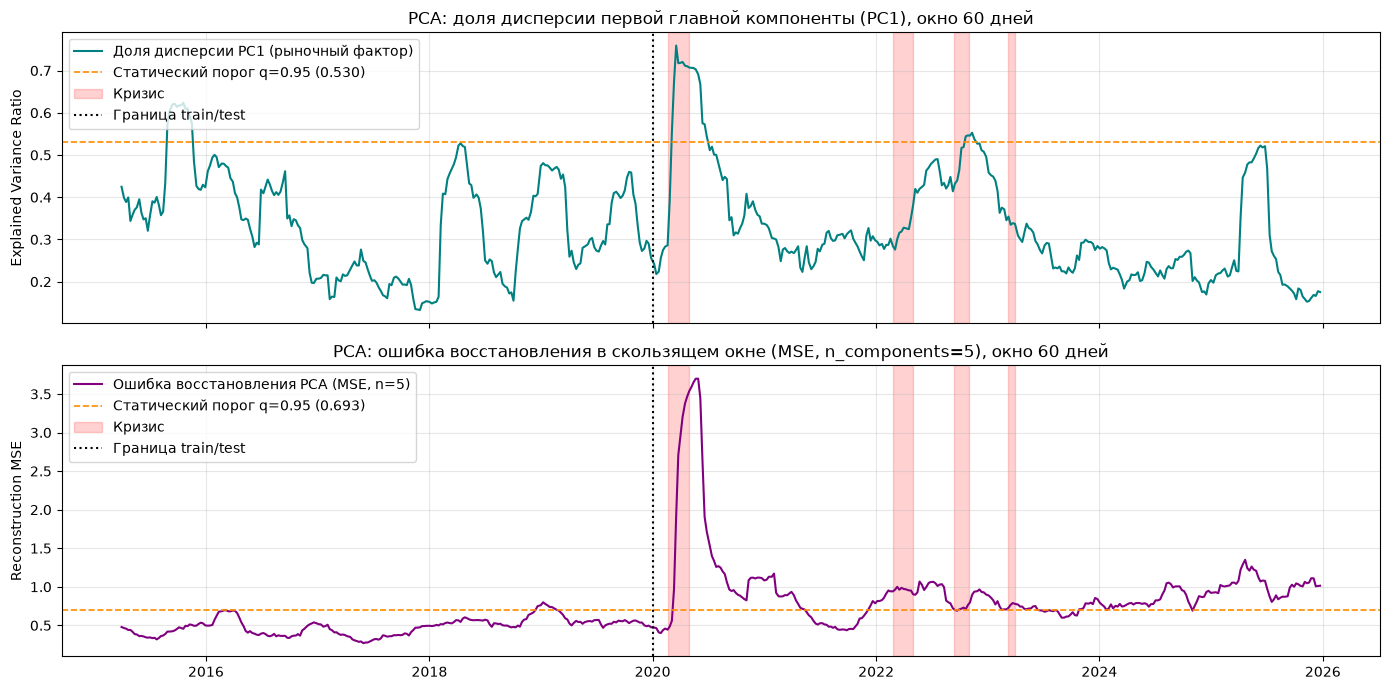

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# 1. Верхний график: Доля дисперсии первой главной компоненты (PC1)
thr_pc1_95 = X_pc1[train_mask].quantile(0.95)
axes[0].plot(X_pc1.index, X_pc1, color="teal", label="Доля дисперсии PC1 (рыночный фактор)")
axes[0].axhline(thr_pc1_95, color="darkorange", linestyle="--", linewidth=1.2, label=f"Статический порог q=0.95 ({thr_pc1_95:.3f})")
axes[0].set_title(f"PCA: доля дисперсии первой главной компоненты (PC1), окно {WINDOW} дней")
axes[0].set_ylabel("Explained Variance Ratio")

# 2. Нижний график: Ошибка восстановления (PCA MSE)
thr_mse_95 = X_mse[train_mask].quantile(0.95)
axes[1].plot(X_mse.index, X_mse, color="purple", label="Ошибка восстановления PCA (MSE, n=5)")
axes[1].axhline(thr_mse_95, color="darkorange", linestyle="--", linewidth=1.2, label=f"Статический порог q=0.95 ({thr_mse_95:.3f})")
axes[1].set_title(f"PCA: ошибка восстановления в скользящем окне (MSE, n_components=5), окно {WINDOW} дней")
axes[1].set_ylabel("Reconstruction MSE")

# Оформление кризисов и границы train/test на обоих графиках
for ax in axes:
    for i, (name, (s, e)) in enumerate(CRISES.items()):
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="red", alpha=0.18, label="Кризис" if i == 0 else None)
    ax.axvline(pd.Timestamp(TRAIN_END), color="black", linestyle=":", linewidth=1.5, label="Граница train/test")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


## 3. Выводы по результатам сравнения Baseline и PCA

По итогам тестирования алгоритмов на выборке 2020–2025 гг. (4 макроэкономических кризиса: COVID-19, геополитический шок и рост ставки ФРС весной 2022 г., инфляционный шок осенью 2022 г., банковский кризис SVB в марте 2023 г.) можно сделать следующие выводы:

1. **Эквивалентность `PCA PC1` и средней корреляции (`mean_corr`):**
   * График и метрики доли дисперсии первой главной компоненты (`PCA PC1`) практически повторяют динамику средней попарной корреляции. Математически это объясняется тем, что на стандартизированных доходностях первое собственное значение корреляционной матрицы напрямую связано со средним уровнем корреляции в системе.
   * Оба индикатора уверенно фиксируют системную синхронизацию рынка («стадный инстикт»), когда большинство акций падает одновременно (COVID-19, весна и осень 2022 г.), но хуже реагируют на локальные отраслевые шоки (например, крах SVB в марте 2023 г., затронувший преимущественно банковский сектор).

2. **Особенности детектора по ошибке восстановления (`PCA MSE`):**
   * В отличие от `PC1`, метод ошибки восстановления оценивает не силу общего рыночного фактора, а **нарушение привычной корреляционной структуры** между секторами относительно спокойного обучающего периода (2015–2019 гг.).
   * *Ограничение статического порога для `PCA MSE`:* После 2020 года общий режим волатильности и межотраслевых связей на рынке США сместился по сравнению с периодом 2015–2019 гг. Из-за этого статический порог (`q=0.95`), откалиброванный только на `train`, склонен давать повышенное число ложных тревог на тестовом периоде (снижение `Precision`). Применение **адаптивного робастного Z-score** нивелирует этот сдвиг режима.

3. **Сравнение правил принятия решений (Статический порог vs Адаптивный Z-score vs PELT):**
   * **Статический порог (`q=0.95` / `q=0.99`)** обеспечивает высокую точность (`Precision memory = 1.000` на бейзлайне) и минимум ложных срабатываний, но пропускает умеренные кризисы (`1/4` или `2/4` пойманных событий), так как опирается на фиксированный уровень стресса из прошлого.
   * **Адаптивный робастный Z-score (`z > 3.0`)** подстраивается под текущий рыночный режим без заглядывания в будущее и позволяет обнаруживать **3 из 4 кризисов** со средней задержкой около `22–23` дней (в рамках 60-дневного окна), ценой появления единичных ложных эпизодов.
   * **Алгоритм PELT** также обнаруживает `3/4` кризисов при `penalty=0.5`, однако является офлайн-методом (использует информацию обо всём временном ряде сразу) и неприменим для сигнализации в реальном времени.

4. **Итоговая рекомендация:**
   Для практического мониторинга системного риска в режиме реального времени наиболее сбалансированным решением является связка **индикатора концентрации риска (`PCA PC1` или `mean_corr`) с адаптивным робастным Z-score**, дополненная контролем ошибки восстановления (`PCA MSE`) для отслеживания структурных сдвигов между секторами.


### 3. IsolationForest solution

In [15]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
iso_score = iso.fit_predict(returns)

### 4. AutoEncoder

#### Базовые методы детекции аномалий (Baseline-модели)

Для корректной оценки эффективности графового автоэнкодера в работе используются два классических (неграфовых) автоэнкодера. Они выполняют разные методологические роли и позволяют отделить вклад рыночной волатильности от изменений в структуре взаимосвязей между активами.

##### 1. Автоэнкодер на дневных доходностях (контрольный метод)

* **Входные данные:** Вектор логарифмических или простых доходностей $N = 89$ акций за один торговый день $t$: $\mathbf{r}_t \in \mathbb{R}^{89}$.
* **Суть подхода:** Модель обучается сжимать и восстанавливать ежедневное распределение доходностей. Ошибка реконструкции отвечает на вопрос: *«Насколько текущие однодневные движения цен отклоняются от типичного рыночного поведения?»*
* **Чувствительность и роль в работе:** Данная модель реагирует преимущественно на амплитуду ценовых колебаний, то есть на **волатильность** рынка. В исследовании она выступает контрольным бенчмарком, позволяющим определить, какая доля рыночных аномалий детектируется исключительно за счет резких скачков цен без учета взаимной динамики активов.

##### 2. Автоэнкодер на скользящих корреляциях (прямой бенчмарк)

* **Входные данные:** Вектор уникальных попарных корреляций (верхний или нижний треугольник корреляционной матрицы), рассчитанных на скользящем окне длиной $W = 60$ торговых дней. Размерность входного вектора составляет $\frac{89 \times 88}{2} = 3916$ признаков.
* **Суть подхода:** Модель восстанавливает привычную конфигурацию линейных связей между акциями. Ошибка реконструкции отвечает на вопрос: *«Насколько необычна текущая структура зависимостей на рынке?»*
* **Чувствительность и роль в работе:** Данный метод реагирует на структурные сдвиги — например, на эффект «схлопывания корреляций» (рост синхронности движений всех акций в периоды кризисов). В работе он служит **прямой точкой сравнения** для графового автоэнкодера: обе модели работают с одними и теми же исходными данными (матрицами корреляций), однако обычный автоэнкодер обрабатывает их как плоский вектор признаков, игнорируя топологию графа.

##### Сравнительная характеристика моделей

| Модель | Входное представление | Основной триггер аномалии | Методологическая роль |
| :--- | :--- | :--- | :--- |
| **AE на доходностях** | Вектор за 1 день ($89$ признаков) | Всплеск рыночной волатильности | Контрольный метод (базовый уровень) |
| **AE на корреляциях** | Вектор за окно 60 дней ($3916$ признаков) | Изменение структуры связей | Прямой бенчмарк для графовой модели |
| **Графовый AE** | Граф на основе матрицы корреляций | Нарушение топологии связей | Основная исследуемая модель |


#### AutoEncoder for correlation window

Признаки: (541, 3486) | fit: 192 окон, val: 36 окон
seed 0: эпох 75, val loss 0.7029, порог 0.8352
seed 1: эпох 90, val loss 0.6987, порог 0.8546
seed 2: эпох 74, val loss 0.7070, порог 0.8529
seed 3: эпох 116, val loss 0.6910, порог 0.8345
seed 4: эпох 97, val loss 0.7075, порог 0.8606

По запускам:


,P strict,R strict,F1 strict,P memory,R memory,F1 memory,Поймано кризисов,"Задержка, дней (среднее)",Ложных эпизодов
Метод,,,,,,,,,
AE seed=0 (q=0.99),0.039,0.233,0.067,0.090,0.254,0.133,4/4,26.750,11
AE seed=1 (q=0.99),0.039,0.200,0.066,0.078,0.190,0.111,2/4,61.500,14
AE seed=2 (q=0.99),0.042,0.233,0.071,0.090,0.238,0.131,3/4,39.333,14
AE seed=3 (q=0.99),0.038,0.233,0.066,0.087,0.254,0.130,3/4,39.333,12
AE seed=4 (q=0.99),0.036,0.200,0.061,0.078,0.206,0.114,3/4,73.333,13


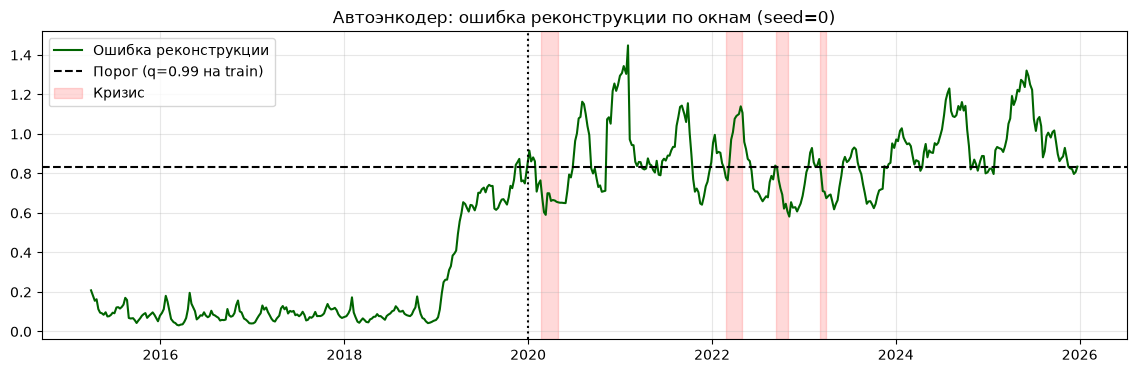

In [16]:
import torch
import torch.nn as nn
from ae_detector import AutoencoderDetector, window_features, split_fit_val

F = window_features(returns, WINDOW, STEP)
assert len(F) == len(df_metrics), "Число окон не совпало с df_metrics"
fit_idx, val_idx = split_fit_val(train_mask, WINDOW, STEP)
print(f"Признаки: {F.shape} | fit: {len(fit_idx)} окон, val: {len(val_idx)} окон")

SEEDS = [0, 1, 2, 3, 4]
Q = 0.99

detectors, before = {}, len(rows)
for s in SEEDS:
    det = AutoencoderDetector(seed=s).fit(F, fit_idx, val_idx)
    det.fit_threshold(F, np.where(train_mask)[0], q=Q)
    detectors[s] = det
    alarm = pd.Series(det.predict(F), index=df_metrics.index)
    add_row(f"AE seed={s} (q={Q})", alarm)
    print(f"seed {s}: эпох {det.n_epochs_}, val loss {det.best_val_loss_:.4f}, порог {det.threshold_:.4f}")

# Сводим запуски в одну строку: среднее по числовым столбцам
ae_df = pd.DataFrame(rows[before:]).set_index("Метод")
rows[:] = rows[:before]
print("\nПо запускам:")
display(ae_df.round(3))

agg = {"Метод": f"Автоэнкодер (среднее по {len(SEEDS)} seed, q={Q})"}
for col in ae_df.select_dtypes(include="number").columns:
    agg[col] = ae_df[col].mean()
agg["Поймано кризисов"] = f'{ae_df["Поймано кризисов"].str.split("/").str[0].astype(int).mean():.1f}/{len(CRISES)}'
rows.append(agg)

results = pd.DataFrame(rows).set_index("Метод")
results.round(3)

# %%
# График ошибки реконструкции для seed=0
det0 = detectors[SEEDS[0]]
err0 = pd.Series(det0.score(F), index=df_metrics.index)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(err0.index, err0, color="darkgreen", label="Ошибка реконструкции")
ax.axhline(det0.threshold_, color="black", linestyle="--", label=f"Порог (q={Q} на train)")
for i, (name, (s_, e_)) in enumerate(CRISES.items()):
    ax.axvspan(pd.Timestamp(s_), pd.Timestamp(e_), color="red", alpha=0.15, label="Кризис" if i == 0 else None)
ax.axvline(pd.Timestamp(TRAIN_END), color="black", linestyle=":")
ax.set_title("Автоэнкодер: ошибка реконструкции по окнам (seed=0)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


##### Solution with AutoEncoder for midday profitability

In [17]:
# 1. Фиксируем случайность для воспроизводимости результатов в ВКР
from torch.utils.data import TensorDataset, DataLoader
from ae_detector import MarketAutoencoder

torch.manual_seed(42)
np.random.seed(42)

# 2. Подготовка данных: обучаем скейлер ТОЛЬКО на train (до 2020 года)
train_returns = returns.loc[returns.index < TRAIN_END]
scaler = StandardScaler().fit(train_returns)

X_train_scaled = scaler.transform(train_returns)
X_all_scaled = scaler.transform(returns)

# Переводим в тензоры PyTorch
train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
all_tensor = torch.tensor(X_all_scaled, dtype=torch.float32)
loader = DataLoader(TensorDataset(train_tensor), batch_size=32, shuffle=True)

model = MarketAutoencoder(input_dim=returns.shape[1], latent_dim=8)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

# 4. Цикл обучения (только на спокойных данных до 2020 года)
model.train()
for epoch in range(50):
    for (batch_x,) in loader:
        optimizer.zero_grad()
        recon_x = model(batch_x)
        loss = criterion(recon_x, batch_x)
        loss.backward()
        optimizer.step()

# 5. Расчёт дневной ошибки восстановления (MSE) для всей истории
model.eval()
with torch.no_grad():
    all_recon = model(all_tensor).numpy()

daily_ae_mse = pd.Series(
    np.mean((X_all_scaled - all_recon) ** 2, axis=1),
    index=returns.index
)

In [18]:
# 1. Агрегируем дневную ошибку восстановления по скользящим окнам (как для PCA MSE)
vals_ae_ret = []
for end in range(WINDOW, len(daily_ae_mse) + 1, STEP):
    vals_ae_ret.append(daily_ae_mse.iloc[end - WINDOW:end].mean())

X_ae_ret = pd.Series(vals_ae_ret, index=df_metrics.index)

# 2. Добавляем статические пороги (q=0.95 и q=0.99)
for q in (0.95, 0.99):
    thr_ae_ret = X_ae_ret[train_mask].quantile(q)
    alarm_ae_ret = (X_ae_ret > thr_ae_ret).astype(int)
    add_row(f"AE на доходностях (q={q}, thr={thr_ae_ret:.3f})", alarm_ae_ret)

# 3. Добавляем адаптивный порог (медиана + MAD)
roll_med_ae = X_ae_ret.shift(1).rolling(LOOKBACK, min_periods=20).median()
roll_mad_ae = X_ae_ret.shift(1).rolling(LOOKBACK, min_periods=20).apply(
    lambda v: np.median(np.abs(v - np.median(v))), raw=True
)
robust_z_ae = (X_ae_ret - roll_med_ae) / (1.4826 * roll_mad_ae)
alarm_ae_ret_adapt = (robust_z_ae > Z_THR).fillna(False).astype(int)
add_row(f"AE на доходностях адаптивный (z>{Z_THR}, lookback={LOOKBACK})", alarm_ae_ret_adapt)

# 4. Обновляем и выводим итоговую сводную таблицу со всеми методами
results = pd.DataFrame(rows).set_index("Метод")
results.round(3)

,P strict,R strict,F1 strict,P memory,R memory,F1 memory,Поймано кризисов,"Задержка, дней (среднее)",Ложных эпизодов
Метод,,,,,,,,,
"Статический порог (q=0.95, thr=0.504)",0.458,0.367,0.407,1.000,0.381,0.552,2/4,25.500,0.0
"Статический порог (q=0.99, thr=0.602)",0.615,0.267,0.372,1.000,0.206,0.342,1/4,20.000,0.0
"Адаптивный порог (z>3.0, lookback=50)",0.255,0.400,0.312,0.489,0.365,0.418,3/4,22.667,1.0
"PELT (penalty=0.5), офлайн",NaN,NaN,NaN,NaN,NaN,NaN,3/4,32.000,1.0
"PCA PC1 (q=0.95, thr=0.530)",0.500,0.367,0.423,1.000,0.349,0.518,2/4,25.500,0.0
"PCA PC1 smoothed (q=0.99, thr=0.617)",0.538,0.233,0.326,1.000,0.206,0.342,1/4,27.000,0.0
"PCA PC1 адаптивный (z>3.0, lookback=50)",0.225,0.300,0.257,0.550,0.349,0.427,2/4,40.000,1.0
"PCA PC1 smoothed адаптивный (z>3.0, lookback=50)",0.186,0.267,0.219,0.488,0.333,0.396,3/4,27.333,1.0
"PCA MSE (n=5, q=0.95, thr=0.693)",0.109,0.900,0.194,0.250,0.984,0.399,4/4,-4.500,4.0


Простые пороговые детекторы по средней корреляции дают точные, но запаздывающие сигналы (задержка 20–27 дней, ложных эпизодов нет), поскольку скользящее окно в 60 дней по построению реагирует на смену режима с лагом. Методы, использующие ошибку реконструкции (PCA, автоэнкодер на доходностях), обнаруживают все четыре кризиса практически без задержки, однако сопровождаются 2–6 ложными эпизодами, что объясняется их чувствительностью к росту волатильности. Автоэнкодер на корреляциях в текущей конфигурации уступает остальным методам (F1 по окнам 0,12), что указывает на необходимость регуляризации при малом числе обучающих окон. Таким образом, преимущество структурного подхода над простыми методами на данном этапе не подтверждено, что мотивирует переход к графовой модели, учитывающей связи между активами явно.

Плотность графов: train 0.211, test 0.206, максимум 0.935 (2020-03-18)
fit: 192 окон, val: 36 окон
seed 0: эпох 295, val loss 1.0744, порог 1.6501
seed 1: эпох 108, val loss 1.0902, порог 1.7870
seed 2: эпох 123, val loss 1.0848, порог 1.7254
seed 3: эпох 123, val loss 1.0836, порог 1.7762
seed 4: эпох 300, val loss 1.0675, порог 1.6561

По запускам:


,P strict,R strict,F1 strict,P memory,R memory,F1 memory,Поймано кризисов,"Задержка, дней (среднее)",Ложных эпизодов
Метод,,,,,,,,,
GAE порог 0.5 seed=0 (q=0.99),0.172,0.700,0.276,0.418,0.810,0.551,4/4,13.250,2
GAE порог 0.5 seed=1 (q=0.99),0.182,0.467,0.262,0.519,0.635,0.571,3/4,31.333,2
GAE порог 0.5 seed=2 (q=0.99),0.181,0.567,0.274,0.479,0.714,0.573,3/4,19.333,3
GAE порог 0.5 seed=3 (q=0.99),0.164,0.400,0.233,0.479,0.556,0.515,3/4,37.000,3
GAE порог 0.5 seed=4 (q=0.99),0.181,0.700,0.288,0.422,0.778,0.547,3/4,10.000,3


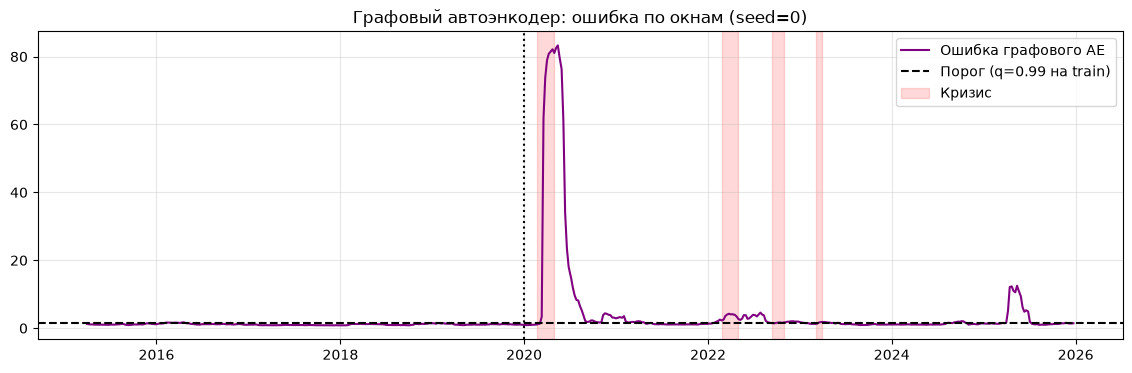

Окно, закончившееся 2020-03-25:


,тикер,z-оценка ошибки
0,KO,404.910004
1,COST,392.100006
2,NEE,387.950012
3,MDLZ,382.399994
4,KMB,362.350006
5,MO,356.730011
6,VZ,352.049988
7,AMT,350.059998
8,BLK,349.850006
9,IBM,349.429993


Окно, закончившееся 2023-03-17:


,тикер,z-оценка ошибки
0,JPM,13.30
1,META,12.88
2,AXP,10.55
3,WFC,8.25
4,BAC,7.56
5,ORCL,6.75
6,MS,6.06
7,MMM,5.83
8,BLK,5.56
9,ABT,5.21


In [22]:
import matplotlib.pyplot as plt
from graph_encoder import GraphAEDetector, build_graph_windows

THRESHOLD = 0.5    # порог |corr| для рёбер
SEEDS = [0, 1, 2, 3, 4]
Q = 0.99

data = build_graph_windows(returns, WINDOW, STEP, THRESHOLD)
assert len(data.A) == len(df_metrics), "Число окон не совпало с df_metrics"
N = data.A.shape[1]

# Проверка: плотность графов в train и в test (в кризис должна расти)
density = data.A.sum(axis=(1, 2)) / (N * (N - 1))
print(f"Плотность графов: train {density[train_mask].mean():.3f}, test {density[test_mask].mean():.3f}, "
      f"максимум {density.max():.3f} ({df_metrics.index[density.argmax()].date()})")

fit_idx, val_idx = split_fit_val(train_mask, WINDOW, STEP)
train_idx = np.where(train_mask)[0]
print(f"fit: {len(fit_idx)} окон, val: {len(val_idx)} окон")

# %%
detectors, before = {}, len(rows)
for s in SEEDS:
    det = GraphAEDetector(seed=s).fit(data, fit_idx, val_idx)
    det.fit_threshold(data, train_idx, q=Q)
    detectors[s] = det
    alarm = pd.Series(det.predict(data), index=df_metrics.index)
    add_row(f"GAE порог {THRESHOLD} seed={s} (q={Q})", alarm)
    print(f"seed {s}: эпох {det.n_epochs_}, val loss {det.best_val_loss_:.4f}, порог {det.threshold_:.4f}")

# Сводим запуски в одну строку: среднее по числовым столбцам
gae_df = pd.DataFrame(rows[before:]).set_index("Метод")
rows[:] = rows[:before]
print("\nПо запускам:")
display(gae_df.round(3))

agg = {"Метод": f"Графовый AE, порог {THRESHOLD} (среднее по {len(SEEDS)} seed, q={Q})"}
for col in gae_df.select_dtypes(include="number").columns:
    agg[col] = gae_df[col].mean()
agg["Поймано кризисов"] = f'{gae_df["Поймано кризисов"].str.split("/").str[0].astype(int).mean():.1f}/{len(CRISES)}'
rows.append(agg)

results = pd.DataFrame(rows).set_index("Метод")
results.round(3)

# %%
# График ошибки окна (макроуровень), seed=0
det0 = detectors[SEEDS[0]]
err0 = pd.Series(det0.score(data), index=df_metrics.index)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(err0.index, err0, color="purple", label="Ошибка графового AE")
ax.axhline(det0.threshold_, color="black", linestyle="--", label=f"Порог (q={Q} на train)")
for i, (name, (s_, e_)) in enumerate(CRISES.items()):
    ax.axvspan(pd.Timestamp(s_), pd.Timestamp(e_), color="red", alpha=0.15, label="Кризис" if i == 0 else None)
ax.axvline(pd.Timestamp(TRAIN_END), color="black", linestyle=":")
ax.set_title("Графовый автоэнкодер: ошибка по окнам (seed=0)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

# %%
# Микроуровень: какие акции сильнее всего выбиваются в выбранных окнах (seed=0)
def top_nodes(det, data, date, k=10):
    pos = df_metrics.index.get_indexer([pd.Timestamp(date)], method="nearest")[0]
    z = det.node_zscores(data, [pos])[0]
    order = np.argsort(-z)[:k]
    print(f"Окно, закончившееся {df_metrics.index[pos].date()}:")
    return pd.DataFrame({"тикер": [data.tickers[i] for i in order], "z-оценка ошибки": z[order].round(2)})

display(top_nodes(det0, data, "2020-03-23"))
display(top_nodes(det0, data, "2023-03-20"))